# River jobs

Runtime = `finalized_at - attempted_at`, wait = `attempted_at - scheduled_at`. River keeps completed jobs for 24h.

In [16]:
%pip install --quiet pandas "psycopg[binary]" python-dotenv matplotlib

Note: you may need to restart the kernel to use updated packages.


In [17]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import psycopg
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv(usecwd=True))
conn = psycopg.connect(
    host=os.getenv("POSTGRES_HOST"), port=os.getenv("POSTGRES_PORT"),
    user=os.getenv("POSTGRES_USER"), password=os.getenv("POSTGRES_PASSWORD"), dbname=os.getenv("POSTGRES_DB"),
    options="-c default_transaction_read_only=on", autocommit=True,
)

def q(sql, params=None):
    with conn.cursor() as cur:
        cur.execute(sql, params)
        return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])

## Runtime per job

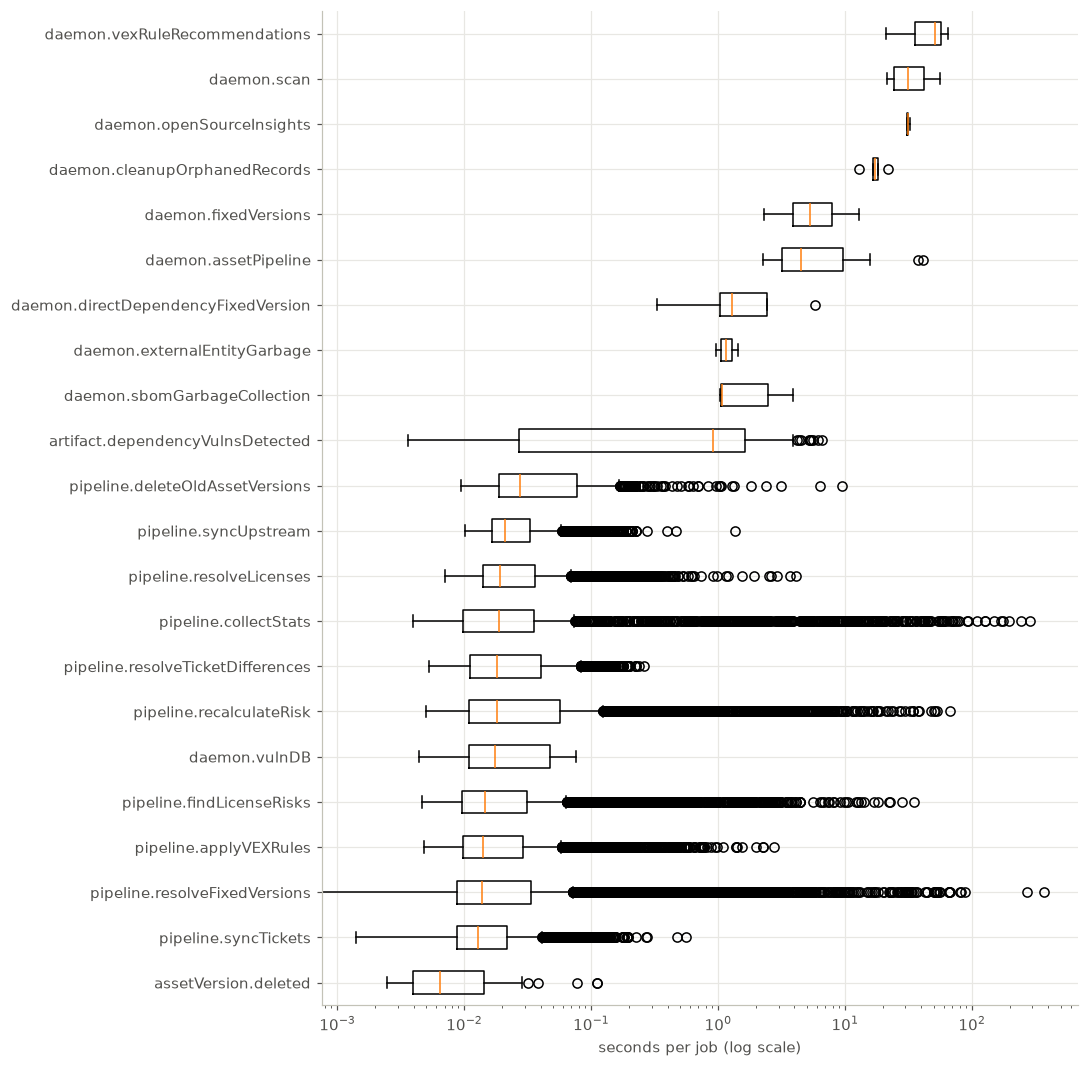

In [18]:
runtime = q("""
    SELECT kind, extract(epoch FROM finalized_at - attempted_at)::float AS seconds
    FROM river_job
    WHERE state = 'completed'
""")
kinds = runtime.groupby("kind")["seconds"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 0.4 * len(kinds) + 1))
ax.boxplot([runtime.loc[runtime["kind"] == k, "seconds"] for k in kinds], orientation="horizontal", tick_labels=kinds)
ax.set_xscale("log")
ax.set_xlabel("seconds per job (log scale)")
plt.tight_layout()
plt.show()

## Runtime and wait per stage

In [19]:
q("""
    SELECT kind,
           count(*) FILTER (WHERE state = 'completed') AS completed,
           count(*) FILTER (WHERE state IN ('available', 'scheduled', 'retryable', 'pending')) AS waiting,
           count(*) FILTER (WHERE state = 'running') AS running,
           count(*) FILTER (WHERE state = 'discarded') AS discarded,
           round(percentile_cont(0.5) WITHIN GROUP (ORDER BY extract(epoch FROM finalized_at - attempted_at)) FILTER (WHERE state = 'completed')::numeric, 2) AS runtime_p50_s,
           round(percentile_cont(0.9) WITHIN GROUP (ORDER BY extract(epoch FROM finalized_at - attempted_at)) FILTER (WHERE state = 'completed')::numeric, 2) AS runtime_p90_s,
           round((sum(extract(epoch FROM finalized_at - attempted_at)) FILTER (WHERE state = 'completed') / 60)::numeric, 1) AS runtime_total_min,
           round(percentile_cont(0.5) WITHIN GROUP (ORDER BY extract(epoch FROM attempted_at - scheduled_at)) FILTER (WHERE attempt = 1)::numeric, 1) AS wait_p50_s,
           round(percentile_cont(0.9) WITHIN GROUP (ORDER BY extract(epoch FROM attempted_at - scheduled_at)) FILTER (WHERE attempt = 1)::numeric, 1) AS wait_p90_s
    FROM river_job
    GROUP BY kind
    ORDER BY runtime_total_min DESC NULLS LAST
""")

,kind,completed,waiting,running,discarded,runtime_p50_s,runtime_p90_s,runtime_total_min,wait_p50_s,wait_p90_s
0,pipeline.collectStats,4117,922,12,0,0.02,0.74,103.6,105.3,164.1
1,pipeline.resolveFixedVersions,7984,0,0,4,0.01,0.16,69.8,302.4,5046.6
2,pipeline.recalculateRisk,5131,0,0,0,0.02,0.24,35.8,107.9,735.7
3,pipeline.findLicenseRisks,6240,0,0,0,0.01,0.12,14.0,739.5,6406.8
4,artifact.dependencyVulnsDetected,299,0,0,0,0.91,2.80,5.2,1.6,225.0
5,pipeline.applyVEXRules,4778,0,0,0,0.01,0.10,3.3,711.1,7389.9
6,daemon.assetPipeline,22,0,0,0,4.53,15.73,3.3,0.0,0.1
7,pipeline.deleteOldAssetVersions,3120,0,0,0,0.03,0.09,3.0,16.8,32.5
8,pipeline.resolveLicenses,3198,0,0,0,0.02,0.11,2.6,900.8,6113.7
9,pipeline.resolveTicketDifferences,5071,18,0,0,0.02,0.06,2.5,171.5,489.6


## Errors

In [21]:
q("""
    SELECT kind, state, left(errors[array_length(errors, 1)]->>'error', 200) AS last_error, count(*) AS jobs
    FROM river_job
    WHERE array_length(errors, 1) > 0
    GROUP BY 1, 2, 3
    ORDER BY jobs DESC
""")

,kind,state,last_error,jobs
0,pipeline.findLicenseRisks,completed,"FindLicenseRisks: could not find license risks: ERROR: insert or update on table ""artifact_license_risks"" violates foreign key constraint ""artifact_license_risks_license_risk_id_fkey"" (SQLSTATE 23...",9
1,pipeline.resolveFixedVersions,discarded,ResolveFixedVersions: could not get vulns for asset: extended protocol limited to 65535 parameters,4
2,daemon.openSourceInsights,completed,Stuck job rescued by JobRescuer,1
3,pipeline.recalculateRisk,completed,RecalculateRiskForVulnerabilities: could not recalculate risk: could not save dependencyVulns: could not execute batch 0 - 3104: ERROR: deadlock detected (SQLSTATE 40P01)\ncould not save dependenc...,1
4,pipeline.recalculateRisk,completed,RecalculateRiskForVulnerabilities: could not recalculate risk: could not save dependencyVulns: could not execute batch 0 - 1031: ERROR: deadlock detected (SQLSTATE 40P01)\ncould not save dependenc...,1
5,pipeline.recalculateRisk,completed,RecalculateRiskForVulnerabilities: could not recalculate risk: could not save dependencyVulns: could not execute batch 0 - 2466: ERROR: deadlock detected (SQLSTATE 40P01),1
6,pipeline.recalculateRisk,completed,RecalculateRiskForVulnerabilities: could not recalculate risk: could not save dependencyVulns: could not execute batch 0 - 425: ERROR: deadlock detected (SQLSTATE 40P01)\ncould not save dependency...,1
7,pipeline.recalculateRisk,completed,RecalculateRiskForVulnerabilities: could not recalculate risk: could not save dependencyVulns: could not execute batch 0 - 2450: ERROR: deadlock detected (SQLSTATE 40P01)\ncould not save dependenc...,1
8,pipeline.recalculateRisk,completed,RecalculateRiskForVulnerabilities: could not recalculate risk: could not save dependencyVulns: could not execute batch 0 - 3104: ERROR: deadlock detected (SQLSTATE 40P01),1
9,pipeline.recalculateRisk,completed,RecalculateRiskForVulnerabilities: could not recalculate risk: could not save dependencyVulns: could not execute batch 0 - 2701: ERROR: deadlock detected (SQLSTATE 40P01)\ncould not save dependenc...,1


## Slowest pipeline runs per asset

In [22]:
q("""
    SELECT args->'payload'->>'assetId' AS asset_id,
           count(*) AS jobs,
           round(sum(extract(epoch FROM finalized_at - attempted_at))::numeric, 1) AS busy_s,
           round(extract(epoch FROM max(finalized_at) - min(attempted_at))::numeric, 1) AS wall_s
    FROM river_job
    WHERE kind LIKE 'pipeline.%' AND state = 'completed'
    GROUP BY 1
    ORDER BY busy_s DESC
    LIMIT 20
""")

,asset_id,jobs,busy_s,wall_s
0,d0164d9c-3005-4622-a531-a314ae972685,20,784.6,9413.1
1,60cf3981-59f2-4b0d-a8b9-b3ecf4eaf224,17,392.7,9334.2
2,a7dca4ae-d5ac-475f-8b70-cb799d2173e7,14,342.2,9337.3
3,5c64a0c0-2184-4ec4-968a-0dce1537f662,18,317.5,9371.3
4,6a29e949-9333-4724-be93-6c7850bf711f,20,313.5,9403.5
5,f293ba8c-3629-4b2e-aeec-427213d429a7,18,259.5,9412.2
6,323c4a73-f89b-4f8c-914c-d69634d4a13e,17,257.6,9327.3
7,a664a4cf-d302-491e-a890-f27d46bb646c,17,230.0,9339.5
8,124fd5e7-f347-4bbf-b799-fe575f824ba3,18,185.2,9349.6
9,f7fa422e-1a57-4895-9bc7-7f32b83371f6,12,181.1,9152.7
